---

# Conference Popularity and Association Pattern Mining pada Dataset DBLP

*Notebook 07: Temporal Association Analysis.*

---

## Kelompok Tugas Besar Data Mining

- Izhar Alif Akbar (18223129)
- Harfhan Ikhtiar (18223123)
- Mahesa Andre (13523140)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Transaksi per Periode**](#3)
4. [**Frequent Itemsets per Periode**](#4)
5. [**Association Rules per Periode**](#5)
6. [**Uji Ketahanan dan Pemilihan Min Support Utama**](#6)
7. [**Perbandingan Rules Antarperiode**](#7)
8. [**Perubahan Tren Publikasi**](#8)

---

# Introduction <a name="1"></a>

---

## Overview

*Notebook ini melihat bagaimana pola asosiasi venue berubah dari waktu ke waktu. Berbeda dengan `04_fpgrowth` dan `05_rules` yang memakai author-based database (satu transaksi per author untuk seluruh 2015-2025), notebook ini memakai author-year-based database dari `02_transactions`: satu transaksi per pasangan (author, tahun), berisi venue tempat author itu publish pada tahun tersebut. Karena tahun menjadi bagian dari transaksi, database dapat dipotong menjadi empat periode.*

## Aim

*Notebook ini bertujuan untuk:*

1. *menjalankan frequent pattern mining dan mengidentifikasi frequent itemsets pada setiap periode (2015-2017, 2018-2020, 2021-2023, 2024-2025).*
2. *membangkitkan association rules untuk setiap periode.*
3. *membandingkan rules antarperiode, lalu mengidentifikasi pola yang bertahan dan pola yang berubah.*
4. *menjelaskan kemungkinan perubahan tren publikasi berdasarkan hasil eksperimen.*

## Approach

*Algoritma yang dipakai hanya FP-Growth. FP-Growth sudah divalidasi terhadap `mlxtend` pada `04_fpgrowth`, dan `06_performance` menunjukkan Apriori menghasilkan itemset yang sama. Rules dibangkitkan dengan min confidence 50%, sama dengan `05_rules`. Fungsi khusus notebook ini (pemotongan periode, penghitungan support langsung dari transaksi, kategori rule, dan pemilihan min support utama) berada di modul `temporal` pada `src/`.*

*Langkahnya:*

1. *Memotong author-year-based database per periode. Penyebut support adalah seluruh transaksi pada periode itu, termasuk transaksi berisi satu venue.*
2. *Menjalankan FP-Growth dan membangkitkan rules pada tiga min support: 0,01%, 0,02%, dan 0,05%. Ambang ini 10 sampai 100 kali lebih rendah daripada `04_fpgrowth` karena transaksi author-year jauh lebih jarang berisi kombinasi (71,0% hanya berisi satu venue, `02_transactions`). Pada min support 0,1% seperti `04_fpgrowth`, periode awal hanya menghasilkan 0 sampai 1 rule.*
3. *Menguji ketahanan: mining diulang setelah transaksi berisi 20 venue atau lebih dalam satu tahun dikosongkan (tetap dihitung pada penyebut).*
4. *Memilih satu min support utama dengan kriteria yang ditetapkan sebelum melihat polanya: setiap periode memiliki minimal 15 rules, dan minimal 80% rules setiap periode lolos uji ketahanan. Dari yang lolos, dipilih ambang terkecil. Jika tidak ada yang lolos, jumlah rules tetap menjadi syarat dan dipilih ambang dengan ketahanan terbaik di antara yang memenuhinya.*
5. *Membandingkan rules antarperiode pada min support utama dengan empat kategori, lalu menghitung support, confidence, dan lift setiap rule di semua periode, termasuk periode tempat rule itu tidak lolos ambang.*

## Kategori Rule

| Kategori | Kemunculan pada empat periode | Contoh pola |
|---|---|---|
| Bertahan | Lolos di keempat periode | ✓✓✓✓ |
| Muncul | Tidak lolos di awal, lalu lolos terus sampai 2024-2025 | ✗✗✓✓, ✗✗✗✓ |
| Hilang | Lolos di awal, lalu tidak lolos sampai 2024-2025 | ✓✓✗✗, ✓✗✗✗ |
| Berselang | Pola lain | ✓✗✓✓, ✗✓✓✗ |

*"Lolos" berarti rule memenuhi min support dan min confidence pada periode itu.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook ini tidak memakai GPU. Prasyaratnya adalah `data/processed/tx_author_year.parquet`, `tx_author_year_index.parquet`, dan `tx_items.csv` dari notebook `02_transactions`. Seluruh mining berjalan dalam beberapa menit.

Sel berikut memasang semua pustaka yang dipakai notebook ini.

In [1]:
%pip install -q --disable-pip-version-check numpy pandas matplotlib pyarrow

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Seluruh `import` untuk notebook ini dikumpulkan di satu sel. Modul proyek di `src/` diimpor setelah `Settings` menetapkan path-nya.

In [2]:
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

## Seed Everything

Mining bersifat deterministik. Seed tetap ditetapkan agar konsisten dengan notebook lain.

In [3]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(42)

## Settings

Seluruh path, periode, ambang, dan warna dipusatkan di kelas `Settings`. Palet warna sama dengan notebook sebelumnya.

In [4]:
class Settings:
    SEED = 42
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

    SRC_DIR = ROOT / "src"
    PROC_DIR = ROOT / "data" / "processed"
    TAB_DIR = ROOT / "outputs" / "tables"
    FIG_DIR = ROOT / "outputs" / "figures"
    OUT_DIR = ROOT / "outputs" / "temporal"

    ITEMS = PROC_DIR / "tx_items.csv"
    TX_LONG = PROC_DIR / "tx_author_year.parquet"
    TX_INDEX = PROC_DIR / "tx_author_year_index.parquet"

    MIN_SUPPORTS = [0.0001, 0.0002, 0.0005]
    MIN_CONFIDENCE = 0.5
    LARGE_TX = 20
    MIN_RULES = 15
    MIN_SURVIVAL = 0.8
    TOP_K = 10

    INK = "#0b0b0b"
    INK_2 = "#52514e"
    MUTED = "#898781"
    GRID = "#e1e0d9"
    BASELINE = "#c3c2b7"
    SURFACE = "#fcfcfb"
    BLUE = "#2a78d6"
    BLUE_LIGHT = "#9ec5f4"
    ORANGE = "#eb6834"
    GRAY = "#b9b8b2"

CFG = Settings()
for d in (CFG.TAB_DIR, CFG.FIG_DIR, CFG.OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(CFG.SRC_DIR))
from fpgrowth import fpgrowth
from fpm_data import load_item_names
from rules import generate_rules, rule_label
from temporal import (PERIODS, choose_main_level, classify_presence, drop_large, period_transactions,
                      rule_metrics)

Gaya grafik dan fungsi bantu diatur sekali di sini. Angka ditulis dengan pemisah ribuan titik dan desimal koma agar konsisten dengan notebook sebelumnya.

In [5]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": CFG.SURFACE, "axes.facecolor": CFG.SURFACE, "savefig.facecolor": CFG.SURFACE,
    "font.size": 9.5, "text.color": CFG.INK, "axes.labelcolor": CFG.INK_2,
    "xtick.color": CFG.INK_2, "ytick.color": CFG.INK_2, "axes.edgecolor": CFG.BASELINE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": CFG.GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 80)


def fmt_id(value, digits=0):
    text = f"{value:,.{digits}f}"
    return text.replace(",", "X").replace(".", ",").replace("X", ".")


def pct_id(value, digits=1):
    return f"{value:.{digits}f}".replace(".", ",") + "%"


def save_fig(fig, name):
    fig.savefig(CFG.FIG_DIR / name)
    plt.show()


def save_table(df, name, index=True):
    df.to_csv(CFG.TAB_DIR / name, index=index)


def tag(ms):
    return f"{ms * 100:g}".replace(".", "p")


def ms_label(ms):
    return pct_id(ms * 100, 2)


def mark(presence):
    return "".join("✓" if p else "✗" for p in presence)


PERIOD_NAMES = list(PERIODS)

## Load Dataset

Tabel panjang `(tid, item)` dan indeks `(tid, author, year)` author-year-based dimuat sekali. Nama venue diambil dari `tx_items.csv`.

In [6]:
names = load_item_names(CFG.ITEMS)
long = pd.read_parquet(CFG.TX_LONG, columns=["tid", "item"])
index = pd.read_parquet(CFG.TX_INDEX, columns=["tid", "year"])
print(f"{fmt_id(len(index))} transaksi author-year, {fmt_id(len(long))} baris (tid, item), "
      f"tahun {index['year'].min()}-{index['year'].max()}")

4.085.594 transaksi author-year, 6.497.515 baris (tid, item), tahun 2015-2025


---

# Transaksi per Periode <a name="3"></a>

---

Database dipotong menurut tahun pada indeks. Setiap periode menjadi database tersendiri dengan penyebut support sendiri. Tabel berikut memprofilkan keempat periode.

In [7]:
tx = {p: period_transactions(long, index, a, b) for p, (a, b) in PERIODS.items()}

profile = pd.DataFrame([{
    "periode": p,
    "tahun": b - a + 1,
    "transaksi": len(t),
    "pct_min_2_item": np.mean([len(s) >= 2 for s in t]),
    "rata_item": np.mean([len(s) for s in t]),
    "tx_besar": sum(len(s) >= CFG.LARGE_TX for s in t),
    "item_maks": max(len(s) for s in t),
} for p, (a, b) in PERIODS.items() for t in [tx[p]]])
save_table(profile, "t7_profil_periode.csv", index=False)
profile.style.format({"transaksi": "{:,}", "pct_min_2_item": "{:.1%}", "rata_item": "{:.2f}", "tx_besar": "{:,}"})

,periode,tahun,transaksi,pct_min_2_item,rata_item,tx_besar,item_maks
0,2015-2017,3,"922,051",29.2%,1.57,137,43
1,2018-2020,3,"1,080,824",28.2%,1.55,272,48
2,2021-2023,3,"1,195,907",28.1%,1.57,511,70
3,2024-2025,2,"886,812",30.8%,1.68,582,85


#### Insights

> 1. Keempat periode berukuran sebanding, sekitar 0,9 sampai 1,2 juta transaksi, dengan porsi transaksi berisi minimal dua venue yang mirip (28 sampai 31%).
> 2. Periode 2024-2025 hanya dua tahun dan data 2025 belum lengkap. Support dihitung relatif terhadap jumlah transaksi periode itu sendiri, sehingga perbedaan ukuran tidak langsung mengubah support, tetapi edisi 2025 yang belum tercatat tidak terkoreksi.
> 3. Kolom `tx_besar` adalah transaksi berisi 20 venue atau lebih dalam satu tahun, yang dipakai pada uji ketahanan di bagian 6.
> 4. Transaksi tidak saling bebas. Author yang aktif setiap tahun muncul di banyak transaksi dan mendapat bobot lebih besar (keterbatasan author-year-based dari `02_transactions`).

---

# Frequent Itemsets per Periode <a name="4"></a>

---

FP-Growth dijalankan pada setiap kombinasi periode dan min support (12 run). Frequent itemsets disimpan di `outputs/temporal/itemsets_<periode>_<tag>.parquet`.

In [8]:
itemsets, results = {}, []
for ms in CFG.MIN_SUPPORTS:
    for p in PERIOD_NAMES:
        res = fpgrowth(tx[p], ms)
        itemsets[(p, ms)] = res.itemsets
        df = pd.DataFrame({"itemset": [sorted(s) for s in res.itemsets], "count": list(res.itemsets.values())})
        df["support"] = df["count"] / len(tx[p])
        df.to_parquet(CFG.OUT_DIR / f"itemsets_{p}_{tag(ms)}.parquet", index=False)
        sizes = pd.Series([len(s) for s in res.itemsets]).value_counts()
        results.append({"min_support": ms, "periode": p, "min_count": res.min_count,
                        "itemsets": len(res.itemsets), "1_item": sizes.get(1, 0), "2_item": sizes.get(2, 0),
                        "3_item": sizes.get(3, 0), "4_plus": int(sizes[sizes.index >= 4].sum()),
                        "terpanjang": int(sizes.index.max()), "detik": res.t_build + res.t_mine})
item_table = pd.DataFrame(results)
save_table(item_table, "t7_itemset_per_periode.csv", index=False)
item_table.style.format({"min_support": "{:.2%}", "detik": "{:.1f}"})

,min_support,periode,min_count,itemsets,1_item,2_item,3_item,4_plus,terpanjang,detik
0,0.01%,2015-2017,93,3045,2123,824,90,8,4,3.5
1,0.01%,2018-2020,109,3286,2154,875,235,22,4,2.9
2,0.01%,2021-2023,120,3882,2080,1067,559,176,5,3.4
3,0.01%,2024-2025,89,8766,1821,1990,2062,2893,7,4.7
4,0.02%,2015-2017,185,1879,1600,259,19,1,4,2.4
5,0.02%,2018-2020,217,1935,1559,322,54,0,3,5.2
6,0.02%,2021-2023,240,2130,1468,452,186,24,4,3.2
7,0.02%,2024-2025,178,3646,1266,875,795,710,6,3.0
8,0.05%,2015-2017,462,854,812,40,2,0,3,1.9
9,0.05%,2018-2020,541,810,729,76,5,0,3,4.4


#### Insights

> 1. Pada ketiga ambang, 2024-2025 memiliki itemset kombinasi paling banyak meskipun jumlah transaksinya paling sedikit.
> 2. Pada 0,02%, itemset berukuran dua atau lebih berjumlah 279, 376, 662, dan 2.380 dari periode pertama sampai terakhir. Itemset berukuran empat atau lebih naik dari 1 menjadi 710.
> 3. Jumlah venue tunggal yang frequent justru turun (1.600, 1.559, 1.468, 1.266), padahal ambang count 2024-2025 paling rendah (178).
> 4. Artinya author makin terkumpul pada venue yang sama, dan venue itu makin sering muncul bersama dalam satu tahun.

Sepuluh itemset berukuran dua atau lebih dengan support tertinggi pada setiap periode (min support 0,02%, ambang utama yang dipilih di bagian 6):

In [9]:
TOP_MS = 0.0002
top_rows = []
for p in PERIOD_NAMES:
    its = sorted(((s, c) for s, c in itemsets[(p, TOP_MS)].items() if len(s) >= 2), key=lambda x: (-x[1], sorted(x[0])))
    for rank, (s, c) in enumerate(its[:CFG.TOP_K], 1):
        top_rows.append({"periode": p, "peringkat": rank, "itemset": " + ".join(sorted(names[i] for i in s)),
                         "count": c, "support": c / len(tx[p])})
top_itemsets = pd.DataFrame(top_rows)
save_table(top_itemsets, "t7_top_itemset.csv", index=False)
top_itemsets.pivot(index="peringkat", columns="periode", values="itemset")

periode,2015-2017,2018-2020,2021-2023,2024-2025
peringkat,,,,
1,GLOBECOM + ICC,CVPR + ECCV,ICML + NeurIPS,ICLR + NeurIPS
2,ACC + CDC,GLOBECOM + ICC,ACL + EMNLP,ICML + NeurIPS
3,ICRA + IROS,ICML + NeurIPS,CVPR + ICCV,CVPR + NeurIPS
4,ECOC + OFC,ICRA + IROS,ICLR + NeurIPS,ACL + EMNLP
5,GLOBECOM + VTC Fall,AAAI + IJCAI,CVPR + NeurIPS,ICLR + ICML
6,ICC + VTC Fall,ACL + EMNLP,AAAI + NeurIPS,AAAI + NeurIPS
7,AAAI + IJCAI,ICASSP + INTERSPEECH,GLOBECOM + ICC,EMNLP + NeurIPS
8,ICASSP + INTERSPEECH,ICLR + NeurIPS,AAAI + CVPR,ACL + NeurIPS
9,CVPR + ICCV,CVPR + NeurIPS,ICLR + ICML,CVPR + ICCV


#### Insights

> 1. Pada 2015-2017, pasangan teratas adalah GLOBECOM + ICC, ACC + CDC, ICRA + IROS, dan ECOC + OFC. Hanya satu dari sepuluh (AAAI + IJCAI) yang memuat AAAI, NeurIPS, ICML, ICLR, ACL, atau EMNLP.
> 2. Pada 2024-2025, sembilan dari sepuluh pasangan teratas memuat salah satu venue itu. Satu-satunya pengecualian adalah CVPR + ICCV.
> 3. Support ICLR + NeurIPS naik dari 0,18% pada 2018-2020 menjadi 1,04% pada 2024-2025, sedangkan GLOBECOM + ICC turun dari peringkat 1 ke luar sepuluh besar.

---

# Association Rules per Periode <a name="5"></a>

---

Rules dibangkitkan dari itemset setiap run dengan min confidence 50% dan disimpan di `outputs/temporal/rules_<periode>_<tag>.parquet`.

In [10]:
rules = {}
rule_rows = []
for ms in CFG.MIN_SUPPORTS:
    for p in PERIOD_NAMES:
        r = generate_rules(itemsets[(p, ms)], len(tx[p]), CFG.MIN_CONFIDENCE, names)
        rules[(p, ms)] = r
        r.assign(antecedent=r["antecedent"].map(list), consequent=r["consequent"].map(list)) \
         .to_parquet(CFG.OUT_DIR / f"rules_{p}_{tag(ms)}.parquet", index=False)
        one = ((r["n_antecedent"] == 1) & (r["n_consequent"] == 1)).sum() if len(r) else 0
        rule_rows.append({"min_support": ms, "periode": p, "rules": len(r), "satu_ke_satu": int(one),
                          "lift_median": r["lift"].median() if len(r) else np.nan})
rule_table = pd.DataFrame(rule_rows)
save_table(rule_table, "t7_rules_per_periode.csv", index=False)
rule_table.pivot(index="periode", columns="min_support", values="rules")

min_support,0.0001,0.0002,0.0005
periode,,,
2015-2017,70,17,2
2018-2020,130,32,4
2021-2023,480,113,25
2024-2025,7741,1874,282


#### Insights

> 1. Jumlah rules naik tajam menuju 2024-2025 pada ketiga ambang. Pada 0,02%, jumlahnya 17, 32, 113, dan 1.874.
> 2. Pada 0,1% seperti `04_fpgrowth`, periode 2015-2017 sampai 2021-2023 hanya menghasilkan 1, 0, dan 3 rules (diuji saat merancang analisis ini), sehingga ambang yang lebih rendah memang diperlukan.

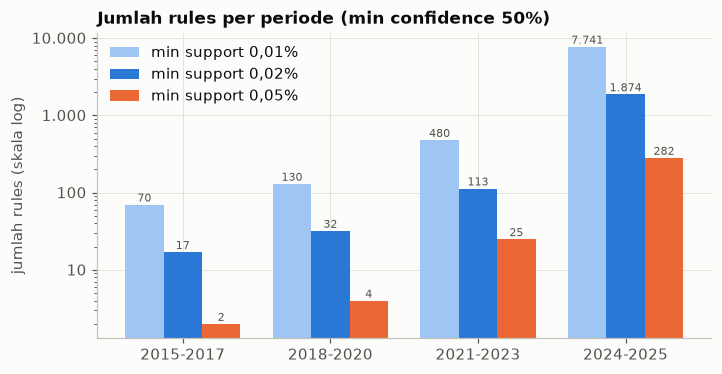

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
x = np.arange(len(PERIOD_NAMES))
colors = {0.0001: CFG.BLUE_LIGHT, 0.0002: CFG.BLUE, 0.0005: CFG.ORANGE}
for k, ms in enumerate(CFG.MIN_SUPPORTS):
    vals = rule_table[rule_table["min_support"] == ms].set_index("periode").loc[PERIOD_NAMES, "rules"]
    bars = ax.bar(x + (k - 1) * 0.26, vals.clip(lower=0.8), width=0.26, color=colors[ms], label=f"min support {ms_label(ms)}")
    for xi, v in zip(x + (k - 1) * 0.26, vals):
        ax.annotate(fmt_id(v), (xi, max(v, 0.8)), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7, color=CFG.INK_2)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_id(v)))
ax.set_xticks(x, PERIOD_NAMES)
ax.set_ylabel("jumlah rules (skala log)")
ax.set_title("Jumlah rules per periode (min confidence 50%)")
ax.legend(loc="upper left")
save_fig(fig, "t7_rules_per_periode.png")

#### Insights

> 1. Median lift rules turun dari 49,1 dan 49,2 pada dua periode awal menjadi 28,0 dan 20,2 pada dua periode berikutnya (min support 0,02%).
> 2. Rules baru berpusat pada venue besar. Sesuai temuan `05_rules`, rule yang menuju venue besar memiliki lift lebih rendah karena support venue tujuannya tinggi.
> 3. Rule satu-ke-satu hampir tidak ada (2, 1, 1, dan 0 pada 0,02%). Dalam satu tahun, publish di satu venue jarang cukup untuk memprediksi venue lain dengan confidence 50%.

Sepuluh rule dengan lift tertinggi pada setiap periode (min support 0,02%):

In [12]:
top_rule_rows = []
for p in PERIOD_NAMES:
    r = rules[(p, TOP_MS)].head(CFG.TOP_K)
    for rank, row in enumerate(r.itertuples(), 1):
        top_rule_rows.append({"periode": p, "peringkat": rank, "rule": row.rule, "support": row.support,
                              "confidence": row.confidence, "lift": row.lift, "count": row.count})
top_rules = pd.DataFrame(top_rule_rows)
save_table(top_rules, "t7_top_rules.csv", index=False)
top_rules.style.format({"support": "{:.3%}", "confidence": "{:.1%}", "lift": "{:.1f}"}).hide(axis="index")

periode,peringkat,rule,support,confidence,lift,count
2015-2017,1,AISTATS + ICML → NeurIPS,0.022%,60.2%,113.8,204
2015-2017,2,ASRU + ICASSP → INTERSPEECH,0.021%,72.6%,104.9,196
2015-2017,3,ECOC + ICTON → OFC,0.039%,66.5%,77.1,360
2015-2017,4,ASRU → INTERSPEECH,0.039%,50.5%,72.9,363
2015-2017,5,ACC + ECC → CDC,0.028%,55.7%,68.0,259
2015-2017,6,ECOC → OFC,0.187%,51.6%,59.8,1721
2015-2017,7,ICC + VTC Fall + WCNC → GLOBECOM,0.021%,63.8%,55.8,192
2015-2017,8,ASRU + INTERSPEECH → ICASSP,0.021%,54.0%,50.2,196
2015-2017,9,ICC + ICCC → GLOBECOM,0.023%,56.1%,49.1,210
2015-2017,10,GLOBECOM + SPAWC → ICC,0.026%,63.1%,48.5,236


#### Insights

> 1. Sepuluh lift tertinggi 2015-2017 tersebar di banyak kelompok venue, antara lain AISTATS + ICML → NeurIPS, ASRU → INTERSPEECH, ECOC → OFC, ACC + ECC → CDC, dan rules GLOBECOM/ICC.
> 2. Pada 2024-2025, seluruh sepuluh lift tertinggi adalah rule empat atau tiga venue menuju dua venue, semuanya memuat ACL atau EMNLP bersama ICLR atau ICML, dengan count hanya 184 sampai 279.
> 3. Bagian 6 menunjukkan sebagian rule ini tidak tahan uji ketahanan.

---

# Uji Ketahanan dan Pemilihan Min Support Utama <a name="6"></a>

---

Sebagian kecil author publish di sangat banyak venue dalam satu tahun, misalnya karena nama umum yang menggabungkan beberapa orang di DBLP (seperti pada `04_fpgrowth`). Transaksi seperti ini dapat membuat kombinasi panjang lolos ambang sendirian. Mining diulang setelah transaksi berisi 20 venue atau lebih dikosongkan, dengan penyebut tetap, dan kolom `survival` adalah porsi rules asli yang tetap ditemukan.

In [13]:
def rule_keys(r):
    return set(zip(r["antecedent"], r["consequent"])) if len(r) else set()

robust_keys, surv_rows = {}, []
for ms in CFG.MIN_SUPPORTS:
    for p in PERIOD_NAMES:
        rc = generate_rules(fpgrowth(drop_large(tx[p], CFG.LARGE_TX), ms).itemsets, len(tx[p]), CFG.MIN_CONFIDENCE)
        robust_keys[(p, ms)] = rule_keys(rc)
        orig = rule_keys(rules[(p, ms)])
        surv_rows.append({"min_support": ms, "period": p, "n_rules": len(orig),
                          "survival": len(orig & robust_keys[(p, ms)]) / len(orig) if orig else 1.0})
survival = pd.DataFrame(surv_rows)
save_table(survival, "t7_robustness.csv", index=False)
survival.pivot(index="period", columns="min_support", values="survival").style.format("{:.0%}")

min_support,0.000100,0.000200,0.000500
period,,,
2015-2017,96%,94%,100%
2018-2020,100%,100%,100%
2021-2023,93%,98%,96%
2024-2025,64%,67%,78%


In [14]:
MAIN_MS, MAIN_PASSED = choose_main_level(survival, CFG.MIN_RULES, CFG.MIN_SURVIVAL)
check = survival.groupby("min_support").agg(rules_min=("n_rules", "min"), survival_min=("survival", "min"))
check["rules_cukup"] = check["rules_min"] >= CFG.MIN_RULES
check["tahan"] = check["survival_min"] >= CFG.MIN_SURVIVAL
print(check)
print(f"\nMin support utama: {ms_label(MAIN_MS)} (semua kriteria terpenuhi: {MAIN_PASSED})")

             rules_min  survival_min  rules_cukup  tahan
min_support                                             
0.0001              70      0.638548         True  False
0.0002              17      0.669157         True  False
0.0005               2      0.776596        False  False

Min support utama: 0,02% (semua kriteria terpenuhi: False)


Sepuluh rule dengan lift tertinggi pada 2024-2025 (min support utama), dengan tanda apakah rule itu tetap ditemukan tanpa transaksi besar:

In [15]:
top24 = rules[("2024-2025", MAIN_MS)].head(CFG.TOP_K).copy()
top24["tahan"] = [(a, c) in robust_keys[("2024-2025", MAIN_MS)] for a, c in zip(top24["antecedent"], top24["consequent"])]
top24[["rule", "count", "confidence", "lift", "tahan"]].style \
    .format({"confidence": "{:.1%}", "lift": "{:.1f}"}).hide(axis="index")

rule,count,confidence,lift,tahan
EMNLP + ICLR + ACM Multimedia + NeurIPS → ACL + ICML,187,50.8%,161.9,False
EMNLP + ICLR + ACM Multimedia + NeurIPS → AAAI + ACL,185,50.3%,142.2,False
ACL + ICML + NAACL-HLT + NeurIPS → EMNLP + ICLR,279,57.8%,141.5,True
EMNLP + ICML + NAACL-HLT + NeurIPS → ACL + ICLR,279,57.1%,136.2,True
EMNLP + ICML + ACM Multimedia + NeurIPS → ACL + ICLR,187,53.7%,128.3,False
ACL + ICML + ACM Multimedia + NeurIPS → EMNLP + ICLR,187,52.1%,127.6,False
AAAI + EMNLP + NAACL-HLT + NeurIPS → ACL + ICLR,212,51.5%,122.9,True
AAAI + ACL + NAACL-HLT + NeurIPS → EMNLP + ICLR,212,50.0%,122.5,True
COLING + EMNLP + ICML → ACL + ICLR,192,50.5%,120.6,False
AAAI + ICML + NAACL-HLT → ACL + ICLR,184,50.1%,119.7,False


#### Insights

> 1. Tidak ada ambang yang memenuhi kedua kriteria, karena survival 2024-2025 hanya 64%, 67%, dan 78% pada 0,01%, 0,02%, dan 0,05%. Ambang 0,05% juga tidak memenuhi syarat jumlah rules (2 dan 4 rules pada dua periode awal).
> 2. Sesuai aturan cadangan, dipilih **0,02%**, ambang dengan ketahanan terbaik di antara yang memiliki minimal 15 rules di setiap periode.
> 3. Pada 2015-2017 sampai 2021-2023, ketahanannya 94% sampai 100%. Hanya 2024-2025 (67%) yang di bawah 80% tanpa 582 transaksi berisi 20 venue atau lebih, sehingga rules yang hanya ada pada 2024-2025 dibaca dengan hati-hati.
> 4. Dari sepuluh lift tertinggi 2024-2025 di atas, hanya empat yang tetap ditemukan tanpa transaksi besar, dan keempat rule yang memuat ACM Multimedia tidak tahan.

---

# Perbandingan Rules Antarperiode <a name="7"></a>

---

Setiap rule pada min support utama diberi tanda kemunculan di keempat periode, lalu diberi kategori. Untuk setiap rule, support, confidence, dan lift juga dihitung langsung dari transaksi di keempat periode, sehingga rule yang tidak lolos dapat dibedakan antara melemah dan sekadar di bawah ambang.

In [16]:
def presence_table(ms):
    pres = {}
    for i, p in enumerate(PERIOD_NAMES):
        for key in rule_keys(rules[(p, ms)]):
            pres.setdefault(key, [False] * len(PERIOD_NAMES))[i] = True
    df = pd.DataFrame([{"antecedent": a, "consequent": c, "pola": mark(v), "kategori": classify_presence(v)}
                       for (a, c), v in pres.items()])
    return df

cat_main = presence_table(MAIN_MS)
for p in PERIOD_NAMES:
    m = rule_metrics(tx[p], zip(cat_main["antecedent"], cat_main["consequent"]))
    cat_main[f"conf_{p}"] = m["confidence"].to_numpy()
    cat_main[f"lift_{p}"] = m["lift"].to_numpy()
    cat_main[f"count_{p}"] = m["count"].to_numpy()
cat_main["rule"] = [rule_label(a, c, names) for a, c in zip(cat_main["antecedent"], cat_main["consequent"])]
cat_main["tahan_2024_2025"] = [(a, c) in robust_keys[("2024-2025", MAIN_MS)] if pat[-1] == "✓" else np.nan
                               for a, c, pat in zip(cat_main["antecedent"], cat_main["consequent"], cat_main["pola"])]
order = {"bertahan": 0, "hilang": 1, "berselang": 2, "muncul": 3}
cat_main = cat_main.sort_values(["kategori", "pola"], key=lambda s: s.map(order) if s.name == "kategori" else s,
                                ignore_index=True)
save_table(cat_main.drop(columns=["antecedent", "consequent"]), "t7_kategori_rules.csv", index=False)

counts = cat_main.groupby(["kategori", "pola"]).size().rename("rules").reset_index()
counts.sort_values("kategori", key=lambda s: s.map(order))

,kategori,pola,rules
6,bertahan,✓✓✓✓,1
7,hilang,✓✓✓✗,1
9,hilang,✓✗✗✗,7
8,hilang,✓✓✗✗,3
3,berselang,✗✓✗✓,3
2,berselang,✗✓✓✗,3
0,berselang,✓✗✓✓,2
1,berselang,✓✗✗✓,3
4,berselang,✗✓✗✗,5
5,berselang,✗✗✓✗,11


#### Insights

> 1. Pada 0,02% terdapat 1.904 rules berbeda dari keempat periode.
> 2. Hampir semuanya muncul (1.865 rules, 98%), dan 1.770 di antaranya hanya lolos pada 2024-2025.
> 3. Hanya satu rule yang bertahan, 11 hilang, dan 27 berselang.

Jumlah per kategori pada ketiga min support, untuk melihat apakah gambaran berubah jika ambang diganti:

In [17]:
sens = pd.DataFrame({ms_label(ms): presence_table(ms)["kategori"].value_counts() for ms in CFG.MIN_SUPPORTS}) \
         .reindex(["bertahan", "hilang", "berselang", "muncul"]).fillna(0).astype(int)
save_table(sens, "t7_kategori_sensitivitas.csv")
sens

,"0,01%","0,02%","0,05%"
kategori,,,
bertahan,13,1,0
hilang,39,11,2
berselang,113,27,7
muncul,7704,1865,281


#### Insights

> 1. Gambaran yang sama terlihat pada ketiga ambang. Rules muncul mencakup 97% sampai 98% dari seluruh rules, sedangkan rules bertahan hanya 13, 1, dan 0.
> 2. Jumlah rules bertahan bergantung kuat pada ambang, dan banyak rule memiliki confidence di sekitar 50%. Yang dapat disimpulkan adalah polanya (sangat sedikit rule yang lolos di semua periode), bukan angka pastinya.

Rule yang bertahan dan yang hilang, dengan confidence di setiap periode (dihitung langsung dari transaksi, termasuk periode saat rule tidak lolos):

In [18]:
CONF = [f"conf_{p}" for p in PERIOD_NAMES]
show = cat_main[cat_main["kategori"].isin(["bertahan", "hilang"])][["kategori", "pola", "rule"] + CONF]
show.style.format({c: "{:.0%}" for c in CONF}).hide(axis="index")

kategori,pola,rule,conf_2015-2017,conf_2018-2020,conf_2021-2023,conf_2024-2025
bertahan,✓✓✓✓,AISTATS + ICML → NeurIPS,60%,61%,61%,58%
hilang,✓✓✓✗,ICC + ICCC → GLOBECOM,56%,58%,59%,nan%
hilang,✓✓✗✗,GLOBECOM + ICCC → ICC,51%,55%,47%,nan%
hilang,✓✓✗✗,ECOC + ICTON → OFC,67%,62%,nan%,64%
hilang,✓✓✗✗,ACC + ECC → CDC,56%,54%,49%,51%
hilang,✓✗✗✗,ECOC → OFC,52%,47%,48%,44%
hilang,✓✗✗✗,GLOBECOM + WCSP → ICC,52%,47%,44%,40%
hilang,✓✗✗✗,ICC + WCSP → GLOBECOM,54%,49%,63%,49%
hilang,✓✗✗✗,GLOBECOM + SPAWC → ICC,63%,49%,59%,54%
hilang,✓✗✗✗,ASRU → INTERSPEECH,50%,44%,44%,47%


#### Insights

> 1. Satu-satunya rule yang bertahan adalah AISTATS + ICML → NeurIPS, dengan confidence yang hampir tetap (60%, 61%, 61%, 58%).
> 2. Dari author-tahun yang publish di AISTATS dan ICML, sekitar 60% juga publish di NeurIPS pada tahun yang sama di setiap periode, sementara count-nya naik dari 204 menjadi 716 (2021-2023).
> 3. Confidence rule yang hilang umumnya tidak jatuh jauh. Setelah tidak lolos, confidence-nya berada di kisaran 40% sampai 64%, sehingga hilangnya lebih tepat dibaca sebagai turun di bawah ambang daripada hubungan yang berhenti.

Rule yang tidak lolos pada suatu periode dapat disebabkan tiga hal: salah satu venue-nya tidak tercatat di DBLP pada periode itu, count kombinasinya di bawah ambang support, atau confidence-nya di bawah 50%. Beberapa venue tidak diadakan atau tidak tercatat setiap tahun (misalnya ICCV pada tahun ganjil dan ECCV pada tahun genap), sehingga kolom `tahun_lengkap` menghitung berapa tahun dalam periode itu yang mencatat semua venue dalam rule.

In [19]:
period_of = {y: p for p, (a, b) in PERIODS.items() for y in range(a, b + 1)}
item_years = long.merge(index, on="tid").groupby("item")["year"].unique().map(set)
min_count = item_table[item_table["min_support"] == MAIN_MS].set_index("periode")["min_count"]


def full_years(items, p):
    a, b = PERIODS[p]
    return sum(all(y in item_years.get(i, set()) for i in items) for y in range(a, b + 1))


reason_rows = []
for _, row in cat_main.iterrows():
    items = set(row["antecedent"]) | set(row["consequent"])
    for i, p in enumerate(PERIOD_NAMES):
        years = full_years(items, p)
        if row["pola"][i] == "✓":
            alasan = "lolos"
        elif years == 0:
            alasan = "konferensi tidak tercatat"
        elif row[f"count_{p}"] < min_count[p]:
            alasan = "support di bawah ambang"
        else:
            alasan = "confidence di bawah 50%"
        reason_rows.append({"kategori": row["kategori"], "rule": row["rule"], "periode": p,
                            "tahun_lengkap": years, "count": row[f"count_{p}"],
                            "confidence": row[f"conf_{p}"], "alasan": alasan})
reasons = pd.DataFrame(reason_rows)
save_table(reasons, "t7_alasan_tidak_lolos.csv", index=False)
pd.crosstab(reasons.loc[reasons["alasan"] != "lolos", "kategori"], reasons.loc[reasons["alasan"] != "lolos", "alasan"])

alasan,confidence di bawah 50%,konferensi tidak tercatat,support di bawah ambang
kategori,,,
berselang,19,1,48
hilang,12,3,13
muncul,51,210,5223


#### Insights

> 1. Pada rule yang hilang, 28 kombinasi (rule, periode) tidak lolos: 13 karena support, 12 karena confidence, dan 3 karena venue-nya tidak tercatat pada periode itu.
> 2. Pada rule yang muncul, hampir semua periode awal tidak lolos karena support (5.223 dari 5.484). Kombinasinya sudah ada, tetapi belum cukup sering.
> 3. Cakupan DBLP per tahun tidak lengkap untuk sebagian venue (ICCC pada 2024-2025, ECOC pada beberapa tahun, ICTON pada 2021-2022, WCSP dan workshop ICCV pada 2025, ICLR sebelum 2017), sehingga rule yang memuat venue ini dapat hilang atau muncul karena data.

Rincian untuk rule yang hilang: jumlah tahun lengkap, count, dan confidence di setiap periode.

In [20]:
lost = reasons[reasons["kategori"] == "hilang"]
lost.pivot(index="rule", columns="periode", values="tahun_lengkap").join(
    lost.pivot(index="rule", columns="periode", values="confidence").round(2), rsuffix=" conf")

C:\Users\Mahesa\AppData\Local\Temp\ipykernel_52832\3803099113.py:2: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  lost.pivot(index="rule", columns="periode", values="tahun_lengkap").join(


periode,2015-2017,2018-2020,2021-2023,2024-2025,2015-2017 conf,2018-2020 conf,2021-2023 conf,2024-2025 conf
rule,,,,,,,,
ACC + ECC → CDC,2,3,3,2,0.56,0.54,0.49,0.51
ASRU → INTERSPEECH,2,1,2,1,0.50,0.44,0.44,0.47
ECOC + ICTON → OFC,2,2,0,1,0.67,0.62,NaN,0.64
ECOC → OFC,2,2,1,1,0.52,0.47,0.48,0.44
GLOBECOM + ICCC → ICC,3,3,3,0,0.51,0.55,0.47,NaN
GLOBECOM + SPAWC → ICC,3,3,3,2,0.63,0.49,0.59,0.54
GLOBECOM + WCNC → ICC,3,3,3,2,0.52,0.48,0.50,0.46
GLOBECOM + WCSP → ICC,3,3,3,1,0.52,0.47,0.44,0.40
ICC + ICCC → GLOBECOM,3,3,3,0,0.56,0.58,0.59,NaN


#### Insights

> 1. **Data tidak tercatat.** DBLP tidak mencatat ICCC pada 2024-2025, sehingga dua rule ICC + ICCC dan GLOBECOM + ICCC hilang karena data, bukan karena tren. ECOC + ICTON → OFC juga hanya memiliki 0 dan 1 tahun lengkap pada dua periode terakhir.
> 2. **Count tetap, database bertambah.** Rules GLOBECOM/ICC dengan SPAWC, WCSP, dan WCNC memiliki count yang relatif datar (misalnya GLOBECOM + WCNC → ICC: 475, 521, 496, 533), sedangkan ambang count naik dari 185 ke 240 pada 2021-2023. Kombinasi ini tidak menghilang, tetapi porsinya di antara seluruh author-tahun mengecil.
> 3. **Confidence di sekitar 50%.** ECOC → OFC, ASRU → INTERSPEECH, dan GLOBECOM + WCNC → ICC berada di kisaran 44% sampai 52%, sehingga lolos atau tidaknya ditentukan selisih kecil.
> 4. Hanya ACC + ECC → CDC yang count-nya juga turun secara absolut (259, 276, 170, 140).

Untuk rule berselang, kolom berikut menandai rule yang jumlah tahun lengkapnya berbeda antarperiode tiga tahun (2015-2017, 2018-2020, 2021-2023), yaitu rule yang memuat venue yang tidak diadakan atau tidak tercatat setiap tahun.

In [21]:
inter = reasons[reasons["kategori"] == "berselang"].pivot(index="rule", columns="periode", values="tahun_lengkap")
inter["pola"] = cat_main.set_index("rule").loc[inter.index, "pola"]
inter["edisi_berubah"] = inter[PERIOD_NAMES[:3]].nunique(axis=1) > 1
save_table(inter, "t7_berselang_edisi.csv")
print(f"Rule berselang dengan jumlah edisi berbeda: {inter['edisi_berubah'].sum()} dari {len(inter)}")
inter.sort_values(["edisi_berubah", "pola"], ascending=[False, True])

Rule berselang dengan jumlah edisi berbeda: 15 dari 27


periode,2015-2017,2018-2020,2021-2023,2024-2025,pola,edisi_berubah
rule,,,,,,
ASRU + ICASSP → INTERSPEECH,2,1,2,1,✓✗✓✓,True
ASRU + INTERSPEECH → ICASSP,2,1,2,1,✓✗✓✓,True
AAAI + COLING → EMNLP,1,2,1,2,✗✓✗✓,True
ECCV + WACV → CVPR,1,2,1,1,✗✓✗✓,True
ACCV + CVPR → ECCV,1,2,1,1,✗✓✗✗,True
ACCV + ECCV → CVPR,1,2,1,1,✗✓✗✗,True
BMVC + ECCV → CVPR,1,2,1,1,✗✓✗✗,True
Odyssey → INTERSPEECH,1,2,1,1,✗✓✗✗,True
BMVC + ICCV → CVPR,2,1,2,1,✗✗✓✗,True


#### Insights

> 1. Sebanyak 15 dari 27 rule berselang memuat venue yang jumlah edisinya berbeda antarperiode, dan sebagian besar lolos pada periode dengan edisi lebih banyak.
> 2. Keenam rule ICCV hanya lolos pada 2021-2023, salah satu dari dua periode dengan dua edisi ICCV (pada 2015-2017 count-nya masih di bawah ambang). Tiga rule ACCV/BMVC dengan ECCV hanya lolos pada 2018-2020, satu-satunya periode tiga tahun dengan dua edisi ECCV.
> 3. SLT → INTERSPEECH, Odyssey → INTERSPEECH, dan AAAI + COLING → EMNLP juga lolos tepat pada periode dengan edisi terbanyak. Pengecualiannya adalah dua rule ASRU dan ECCV + WACV → CVPR, yang juga lolos pada 2024-2025 dengan satu edisi.
> 4. Pada author-year-based database, venue yang tidak diadakan setiap tahun hanya dapat berpasangan pada tahun penyelenggaraannya, sehingga perbandingan antarperiode untuk venue ini terutama mencerminkan jadwal, bukan perubahan minat.
> 5. Sisanya, 12 rule (NLP, AAAI, dan GLOBECOM/ICC), memiliki edisi lengkap di setiap periode dan berselang karena confidence atau support-nya berada di sekitar ambang.

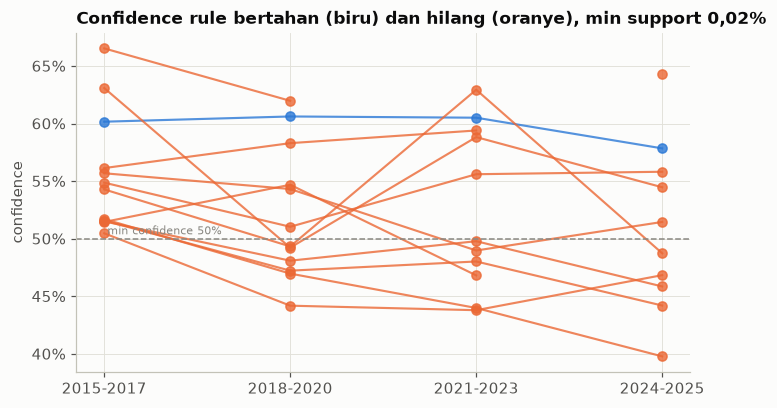

In [22]:
sub = cat_main[cat_main["kategori"].isin(["bertahan", "hilang"])]
fig, ax = plt.subplots(figsize=(7.2, 4.0))
for _, row in sub.iterrows():
    y = [row[f"conf_{p}"] for p in PERIOD_NAMES]
    color = CFG.BLUE if row["kategori"] == "bertahan" else CFG.ORANGE
    ax.plot(PERIOD_NAMES, y, marker="o", color=color, alpha=0.8, linewidth=1.4)
ax.axhline(CFG.MIN_CONFIDENCE, color=CFG.MUTED, linestyle="--", linewidth=1)
ax.annotate("min confidence 50%", (0, CFG.MIN_CONFIDENCE), xytext=(2, 3), textcoords="offset points",
            fontsize=7.5, color=CFG.MUTED)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: pct_id(v * 100, 0)))
ax.set_ylabel("confidence")
ax.set_title(f"Confidence rule bertahan (biru) dan hilang (oranye), min support {ms_label(MAIN_MS)}")
save_fig(fig, "t7_rules_bertahan_hilang.png")

---

# Perubahan Tren Publikasi <a name="8"></a>

---

Untuk melihat venue mana yang mendorong perubahan, setiap rule dihitung sekali untuk setiap venue yang ada di antecedent atau consequent-nya. Tabel berikut menunjukkan venue yang paling sering terlibat di setiap kategori.

In [23]:
inv_rows = []
for row in cat_main.itertuples():
    for i in set(row.antecedent) | set(row.consequent):
        inv_rows.append({"kategori": row.kategori, "konferensi": names[i]})
inv = pd.DataFrame(inv_rows).groupby(["kategori", "konferensi"]).size().rename("rules").reset_index()
inv["porsi"] = inv["rules"] / inv["kategori"].map(cat_main["kategori"].value_counts())
inv = inv.sort_values(["kategori", "rules"], ascending=[True, False])
save_table(inv, "t7_konferensi_kategori.csv", index=False)
inv.groupby("kategori").head(8).style.format({"porsi": "{:.0%}"}).hide(axis="index")

kategori,konferensi,rules,porsi
berselang,CVPR,11,41%
berselang,ICCV,6,22%
berselang,AAAI,5,19%
berselang,GLOBECOM,5,19%
berselang,ICC,5,19%
berselang,ACL,4,15%
berselang,ECCV,4,15%
berselang,EMNLP,4,15%
bertahan,AISTATS,1,100%
bertahan,ICML,1,100%


#### Insights

> 1. Rules yang muncul didominasi venue yang tumbuh paling cepat pada `01_eda` (NeurIPS, ICML, EMNLP, ACL, CVPR, dan ICLR) ditambah AAAI.
> 2. NeurIPS terlibat pada 67% rules muncul, ICLR 47%, ACL 45%, AAAI 43%, EMNLP 42%, ICML 40%, dan CVPR 35%.
> 3. Rules yang hilang didominasi GLOBECOM dan ICC (masing-masing 64%).

Rules muncul menurut periode pertama kali lolos, dan porsinya yang tahan uji ketahanan pada 2024-2025:

In [24]:
emerge = cat_main[cat_main["kategori"] == "muncul"].groupby("pola") \
    .agg(rules=("rule", "size"), tahan_2024_2025=("tahan_2024_2025", "mean")).reset_index()
emerge.style.format({"tahan_2024_2025": "{:.0%}"}).hide(axis="index")

pola,rules,tahan_2024_2025
✗✓✓✓,16,94%
✗✗✓✓,79,95%
✗✗✗✓,1770,65%


#### Insights

> 1. Rules yang muncul sejak 2018-2020 (16 rules) atau 2021-2023 (79 rules) bertahan sampai 2024-2025, dan 94% sampai 95% di antaranya tahan uji ketahanan. Ini adalah bagian tren yang paling dapat dipercaya.
> 2. Rules yang hanya ada pada 2024-2025 (1.770) jauh lebih rapuh. Hanya 65% yang tahan, dan data 2025 belum lengkap.
> 3. Secara keseluruhan, kombinasi venue dalam satu tahun makin terpusat pada NeurIPS, ICLR, ICML, ACL, EMNLP, AAAI, dan CVPR. Tren yang tahan uji adalah 95 rules yang muncul sejak 2018-2023.

Venue computer vision ICCV dan ECCV diadakan bergantian, sehingga jumlah edisinya per periode berbeda. Jumlah author unik per tahun berikut dipakai untuk membaca rules computer vision yang berselang.

In [25]:
ids = {n: i for i, n in names.items() if n in ("ICCV", "ECCV", "CVPR")}
yearly = long[long["item"].isin(ids.values())].merge(index, on="tid") \
    .groupby(["item", "year"]).size().unstack(0).rename(columns={i: n for n, i in ids.items()}).fillna(0).astype(int)
yearly["periode"] = [next(p for p, (a, b) in PERIODS.items() if a <= y <= b) for y in yearly.index]
save_table(yearly, "t7_cv_per_tahun.csv")
yearly

item,CVPR,ECCV,ICCV,periode
year,,,,
2015,2078,0,1543,2015-2017
2016,2470,1986,0,2015-2017
2017,3274,0,1959,2015-2017
2018,4063,3770,0,2018-2020
2019,6191,0,3627,2018-2020
2020,6961,6001,0,2018-2020
2021,7469,0,5971,2021-2023
2022,9938,7869,0,2021-2023
2023,11691,0,8439,2021-2023


#### Insights

> 1. ICCV hanya tercatat pada tahun ganjil dan ECCV pada tahun genap.
> 2. Akibatnya 2015-2017 dan 2021-2023 memiliki dua edisi ICCV dan satu edisi ECCV, sedangkan 2018-2020 sebaliknya, sehingga pola ini menjelaskan rules computer vision yang berselang.
> 3. CVPR tercatat setiap tahun.